<a href="https://colab.research.google.com/github/Indhirayc/PBL_Kelompok1_LeafItToMe/blob/feature%2Fml-training/machine_learning/notebooks/03_data_augmentation_split.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import userdata

token = userdata.get('GITHUB_TOKEN')

if token:
    print("Token berhasil dibaca")
else:
    print("Token belum ditemukan")

SecretNotFoundError: Secret GITHUB_TOKEN does not exist.

In [ ]:
from google.colab import userdata
import subprocess
import base64

token = userdata.get('GITHUB_TOKEN')

if not token:
    raise ValueError(
        "GITHUB_TOKEN tidak ditemukan. "
        "Periksa nama secret dan aktifkan Akses notebook."
    )

auth = base64.b64encode(
    f"x-access-token:{token}".encode()
).decode()

repo_url = "https://github.com/Indhirayc/PBL_Kelompok1_LeafItToMe.git"

result = subprocess.run(
    [
        "git",
        "-c",
        f"http.extraheader=AUTHORIZATION: basic {auth}",
        "clone",
        repo_url
    ],
    text=True,
    capture_output=True
)

print(result.stdout)
print(result.stderr)

if result.returncode == 0:
    print("Repository berhasil di-clone!")
else:
    print("Clone gagal. Periksa izin token.")

SecretNotFoundError: Secret GITHUB_TOKEN does not exist.

In [ ]:
%cd /content/PBL_Kelompok1_LeafItToMe

[Errno 2] No such file or directory: '/content/PBL_Kelompok1_LeafItToMe'
/content


In [ ]:
!git status
!ls

fatal: not a git repository (or any of the parent directories): .git
sample_data


In [ ]:
!git checkout -b feature/ml-training

fatal: not a git repository (or any of the parent directories): .git


In [ ]:
!git branch

fatal: not a git repository (or any of the parent directories): .git


In [ ]:
from pathlib import Path

folders = [
    "machine_learning/notebooks",
    "machine_learning/models",
    "machine_learning/results",
    "dataset"
]

for folder in folders:
    Path(folder).mkdir(parents=True, exist_ok=True)

print("Struktur folder berhasil dibuat.")

Struktur folder berhasil dibuat.


In [ ]:
Path("machine_learning/README.md").write_text(
    """# Machine Learning LeafItToMe

Folder ini berisi notebook, model, dan hasil evaluasi machine learning.

## Struktur

- `notebooks/` — notebook Google Colab
- `models/` — model hasil training
- `results/` — grafik dan hasil evaluasi
""",
    encoding="utf-8"
)

Path("dataset/README.md").write_text(
    """# Dataset LeafItToMe

Dataset disimpan di Google Drive bersama dan tidak diunggah langsung ke GitHub.

Setiap anggota harus memperoleh akses ke folder dataset melalui akun Google
masing-masing.
""",
    encoding="utf-8"
)

Path("machine_learning/notebooks/.gitkeep").touch()
Path("machine_learning/models/.gitkeep").touch()
Path("machine_learning/results/.gitkeep").touch()

print("File README dan .gitkeep berhasil dibuat.")

File README dan .gitkeep berhasil dibuat.


In [ ]:
!find . -maxdepth 3 -type f

./.config/config_sentinel
./.config/configurations/config_default
./.config/active_config
./.config/.last_update_check.json
./.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
./.config/.last_opt_in_prompt.yaml
./.config/gce
./.config/.last_survey_prompt.yaml
./.config/default_configs.db
./dataset/README.md
./machine_learning/results/.gitkeep
./machine_learning/models/.gitkeep
./machine_learning/README.md
./machine_learning/notebooks/.gitkeep
./sample_data/README.md
./sample_data/anscombe.json
./sample_data/california_housing_train.csv
./sample_data/mnist_train_small.csv
./sample_data/mnist_test.csv
./sample_data/california_housing_test.csv


In [ ]:
!git config user.name "Indhira Yuantika Christy"
!git config user.email "indhirayuantikac1176@gmail.com"

fatal: not in a git directory
fatal: not in a git directory


In [ ]:
!git add .
!git commit -m "ml: add machine learning project structure"

fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git


In [ ]:
result_push = subprocess.run(
    [
        "git",
        "-c",
        f"http.extraheader=AUTHORIZATION: basic {auth}",
        "push",
        "-u",
        "origin",
        "feature/ml-training"
    ],
    text=True,
    capture_output=True
)

print(result_push.stdout)
print(result_push.stderr)

NameError: name 'auth' is not defined

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path

DATASET_DIR = Path('/content/drive/MyDrive/dataset')

if DATASET_DIR.exists():
    print('Dataset berhasil ditemukan.')
    print('Lokasi dataset:', DATASET_DIR)
else:
    raise FileNotFoundError(
        'Folder "data set" tidak ditemukan. '
        'Pastikan folder sudah dibagikan dan shortcut sudah ditambahkan ke My Drive.'
    )

Dataset berhasil ditemukan.
Lokasi dataset: /content/drive/MyDrive/dataset


Total Kelas  : 5
Total Gambar : 13781

Distribusi per kelas:
 - Bacterial_spot: 2827 gambar
 - Late_blight: 3113 gambar
 - Leaf_Mold: 2754 gambar
 - Tomato_Yellow_Leaf_Curl_Virus: 2036 gambar
 - healthy: 3051 gambar


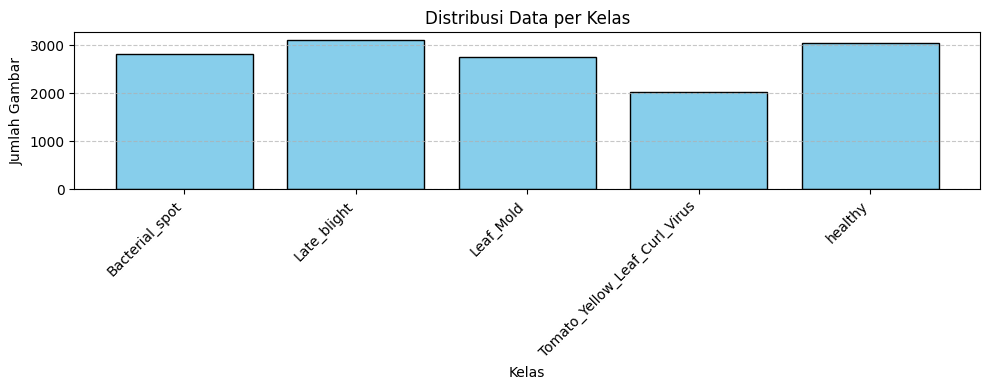

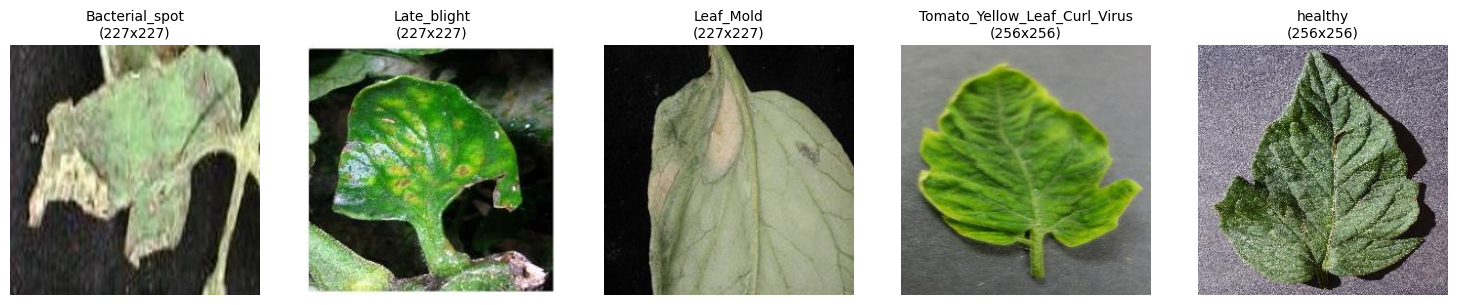

In [ ]:
import os
import glob
import matplotlib.pyplot as plt
from PIL import Image

# Path
DATASET_DIR = '/content/drive/MyDrive/dataset'

# Ekstensi gambar yang didukung
valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

# Ambil daftar kelas dan hitung distribusi gambar
class_counts = {}
for class_name in sorted(os.listdir(DATASET_DIR)):
    class_path = os.path.join(DATASET_DIR, class_name)
    if os.path.isdir(class_path):
        images = [f for f in os.listdir(class_path) if f.lower().endswith(valid_extensions)]
        class_counts[class_name] = len(images)

total_images = sum(class_counts.values())
total_classes = len(class_counts)

print(f"Total Kelas  : {total_classes}")
print(f"Total Gambar : {total_images}\n")
print("Distribusi per kelas:")
for cls, count in class_counts.items():
    print(f" - {cls}: {count} gambar")

# Visualisasi Distribusi Data (Bar Chart)
plt.figure(figsize=(10, 4))
plt.bar(class_counts.keys(), class_counts.values(), color='skyblue', edgecolor='black')
plt.title('Distribusi Data per Kelas')
plt.xlabel('Kelas')
plt.ylabel('Jumlah Gambar')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Contoh Gambar dari Tiap Kelas
num_cols = min(5, total_classes)
num_rows = (total_classes + num_cols - 1) // num_cols

fig, axes = plt.subplots(num_rows, num_cols, figsize=(3 * num_cols, 3 * num_rows))
if total_classes == 1:
    axes = [axes]
else:
    axes = axes.flatten()

for idx, (cls, count) in enumerate(class_counts.items()):
    class_path = os.path.join(DATASET_DIR, cls)
    image_files = [f for f in os.listdir(class_path) if f.lower().endswith(valid_extensions)]

    ax = axes[idx]
    if image_files:
        sample_img_path = os.path.join(class_path, image_files[0])
        img = Image.open(sample_img_path)
        ax.imshow(img)
        ax.set_title(f"{cls}\n({img.size[0]}x{img.size[1]})", fontsize=10)
    else:
        ax.text(0.5, 0.5, 'Kosong', ha='center', va='center')
    ax.axis('off')

# Matikan subplot sisa jika ada slot kosong di grid
for ax in axes[idx + 1:]:
    ax.axis('off')

plt.tight_layout()
plt.show()

## Preprocessing data

In [ ]:
#Melakukan Cleaning data
import os
from PIL import Image

# os.remove(file_path)

dataset_path = '/content/drive/MyDrive/dataset'
corrupted_files = []

print("Memulai proses cleaning data...")

# Menelusuri setiap folder kelas di dalam dataset
for folder_name in os.listdir(dataset_path):
    folder_path = os.path.join(dataset_path, folder_name)

    # Pastikan yang dibaca adalah folder (bukan file nyasar)
    if os.path.isdir(folder_path):
        for file_name in os.listdir(folder_path):
            file_path = os.path.join(folder_path, file_name)

            try:
                # Mencoba membuka gambar dan memverifikasi integritasnya
                img = Image.open(file_path)
                img.verify()
            except (IOError, SyntaxError) as e:
                print(f"Gambar rusak ditemukan: {file_path}")
                corrupted_files.append(file_path)

                # Menghapus file yang rusak (hapus tanda '#' di bawah ini jika ingin otomatis dihapus)
                os.remove(file_path)

if len(corrupted_files) == 0:
    print("Cleaning selesai! Tidak ada gambar yang rusak. Dataset Anda aman.")
else:
    print(f"Cleaning selesai! Total {len(corrupted_files)} gambar rusak telah dihapus.")

Memulai proses cleaning data...
Cleaning selesai! Tidak ada gambar yang rusak. Dataset Anda aman.


In [ ]:
import tensorflow as tf

dataset_path = '/content/drive/MyDrive/dataset'
batch_size = 32
img_size = (244, 244)

# Memuat dataset gambar dari direktori
train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,#20% untuk validasi
    subset="training",
    seed=123, #Digunakan untuk pemisah antar data agar konsisten
    image_size=img_size,
    batch_size=batch_size
)

# Memuat data Validasi
val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed = 123,
    image_size=img_size,
    batch_size=batch_size
)

#Layer Normalisasi (mengubah piksel dari 1-255 menjadi 0-1)
normalization_layer = tf.keras.layers.Rescaling(1./255)

#Menambahkan layer normalisasi ke dataset
train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))

#optimasi peforma
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

print("Preprocessing Selesai. Dataset Siap dilatih!")

Found 13781 files belonging to 5 classes.
Using 11025 files for training.
Found 13781 files belonging to 5 classes.
Using 2756 files for validation.
Preprocessing Selesai. Dataset Siap dilatih!


##Pembagian Data

In [ ]:
import os
import shutil
import random
from pathlib import Path

# Path dataset dari notebook sebelumnya
SOURCE_DIR = Path(dataset_path)

# Folder untuk menyimpan hasil pembagian
OUTPUT_DIR = Path("/content/drive/MyDrive/dataset")

# Persentase pembagian
TRAIN_RATIO = 0.80
VAL_RATIO = 0.10
TEST_RATIO = 0.10

# Agar hasil pembagian konsisten
random.seed(42)

# Ekstensi file gambar
IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

print("Dataset :", SOURCE_DIR)
print("Output  :", OUTPUT_DIR)

Dataset : /content/drive/MyDrive/dataset
Output  : /content/drive/MyDrive/dataset


In [ ]:
classes = sorted([
    folder.name
    for folder in SOURCE_DIR.iterdir()
    if folder.is_dir()
])

print("Kelas dataset:")
for i, name in enumerate(classes, 1):
    print(i, name)

Kelas dataset:
1 Bacterial_spot
2 Late_blight
3 Leaf_Mold
4 Tomato_Yellow_Leaf_Curl_Virus
5 healthy
6 test
7 train
8 validation


In [ ]:
for split in ["train", "validation", "test"]:
    for class_name in classes:
        folder = OUTPUT_DIR / split / class_name
        folder.mkdir(parents=True, exist_ok=True)

print("Folder dataset berhasil dibuat.")

Folder dataset berhasil dibuat.


In [ ]:
for name in classes:
    folder = SOURCE_DIR / name

    images = [
        f for f in folder.iterdir()
        if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
    ]

    random.shuffle(images)

    total = len(images)

    train_end = int(total * 0.80)

    validation_end = int(total * 0.90)

    train = images[:train_end]
    validation = images[train_end:validation_end]

    test = images[validation_end:]

    print(
        f"{name}: "
        f"total={total}, "
        f"train={len(train)}, "
        f"validation={len(validation)}, "
        f"test={len(test)}"
    )

    for image in train:
        shutil.copy2(
            image,
            OUTPUT_DIR / "train" / name / image.name
        )

    for image in validation:
        shutil.copy2(
            image,
            OUTPUT_DIR / "validation" / name / image.name
        )

    for image in test:
        shutil.copy2(
            image,
            OUTPUT_DIR / "test" / name / image.name
        )

print("Pembagian dataset selesai.")

Bacterial_spot: total=2827, train=2261, validation=283, test=283
Late_blight: total=3113, train=2490, validation=311, test=312
Leaf_Mold: total=2754, train=2203, validation=275, test=276
Tomato_Yellow_Leaf_Curl_Virus: total=2036, train=1628, validation=204, test=204
healthy: total=3051, train=2440, validation=305, test=306
test: total=0, train=0, validation=0, test=0
train: total=0, train=0, validation=0, test=0
validation: total=0, train=0, validation=0, test=0
Pembagian dataset selesai.


In [ ]:
for split in ["train", "validation", "test"]:
    total = 0

    for name in classes:
        folder = OUTPUT_DIR / split / name

        jumlah = len([
            f for f in folder.iterdir()
            if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
        ])

        total += jumlah

    print(f"{split}: {total} gambar")

train: 13212 gambar
validation: 2604 gambar
test: 2627 gambar


In [ ]:
jumlah_data = {}

for split in ["train", "validation", "test"]:
    total = 0

    for name in classes:
        folder = OUTPUT_DIR / split / name

        total += len([
            f for f in folder.iterdir()
            if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
        ])

    jumlah_data[split] = total

total = sum(jumlah_data.values())

print("\nHasil pembagian:")

for split, jumlah in jumlah_data.items():
    persen = jumlah / total * 100
    print(f"{split}: {jumlah} gambar ({persen:.2f}%)")


Hasil pembagian:
train: 13212 gambar (71.64%)
validation: 2604 gambar (14.12%)
test: 2627 gambar (14.24%)


In [51]:
import tensorflow as tf
from tensorflow.keras import layers
import matplotlib.pyplot as plt

In [48]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="data_augmentation")

print("Data augmentation berhasil dibuat.")

Data augmentation berhasil dibuat.


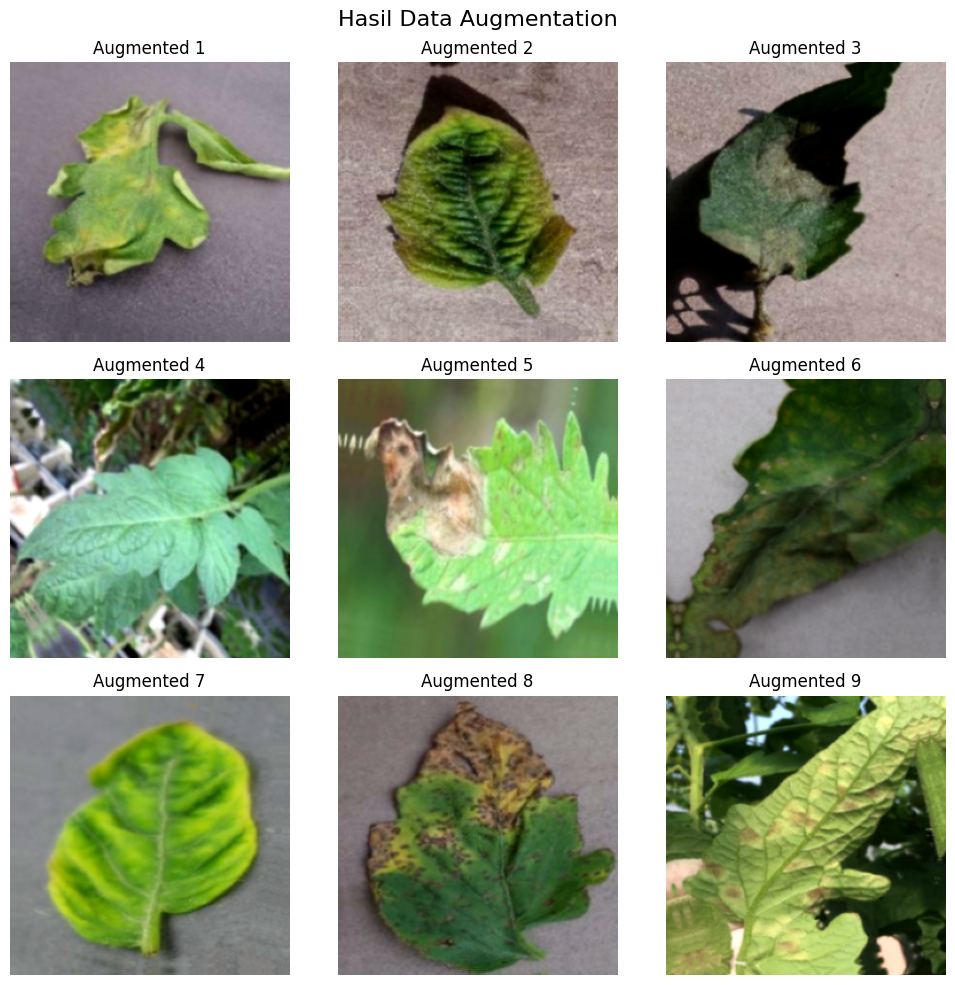

In [57]:
plt.figure(figsize=(10, 10))

for images, labels in train_ds.take(1):

    for i in range(9):

        # Ambil gambar
        image = images[i]

        # Tambahkan dimensi batch
        image = tf.expand_dims(image, axis=0)

        # Terapkan augmentasi
        augmented_image = data_augmentation(
            image,
            training=True
        )

        # Tampilkan gambar
        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(
            augmented_image[0].numpy()
        )

        plt.title(
            f"Augmented {i+1}"
        )

        plt.axis("off")

plt.suptitle(
    "Hasil Data Augmentation",
    fontsize=16
)

plt.tight_layout()
plt.show()